# Slide 17: the test-case KBM's GS2 eigenfunction, real and imaginary parts

Fusion_PhD-qp5.31 (STEP GK talk, 2 Nov 2026). The single KBM of slides 17-18 (SPR-045 `kbm_free` GS2 sample_0818, Fusion_PhD
`results/spr045_single_kbm`). Plotting standard for a mode (user, 2026-11-01): one panel per field, Re and Im on each, no $|\cdot|$.

The `kbm_free` `pyroscan.nc` holds only $|{\rm field}|^2$ (time-averaged), so this one run was re-saved by pyro with its complex
final-time fields (`time_mode="last"`; Fusion_PhD `results/talk_20261102/runs/resave_gs2_complex.py`) to
`GS2/Runs/single_mode_spr045/SPR-045/complex_sample_0818/pyroscan.nc` on the scratch tree.

**Phase convention: pyro's.** pyro divides every field by $\phi$ at the $\theta$ of its $|\phi|$ maximum, so $\phi$ is real there; both
fields are then divided by $\max|\phi|$ here, so $\phi$ peaks at 1.

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
# slide-readable at the saved size, white background (user, 2026-11-01)
plt.rcParams.update({"font.size": 20, "axes.labelsize": 22, "axes.titlesize": 22, "xtick.labelsize": 20, "ytick.labelsize": 20,
                     "legend.fontsize": 19, "lines.linewidth": 2.5, "lines.marker": "", "figure.facecolor": "white",
                     "axes.facecolor": "white", "savefig.facecolor": "white", "savefig.dpi": 200})
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
plots_dir = ROOT / "Plots" / "stepgk_20261102"
plots_dir.mkdir(parents=True, exist_ok=True)


def log_xticks(ax, ticks):
    ax.set_xticks(ticks)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.minorticks_off()
from pyrokinetics import PyroHypercube

gs2_runs = Path(os.environ["GYRO_DATA_OUTPUT"]) / "GS2/Runs/LATIN_HYPERCUBE/SPR-045/kbm_free"
complex_leaf = Path(os.environ["GYRO_DATA_OUTPUT"]) / "GS2/Runs/single_mode_spr045/SPR-045/complex_sample_0818"
gs2_scan = PyroHypercube.from_directory(gs2_runs, pattern="sample_0818", params=["ky"], gk_code="GS2", file_name="input.in")
gs2_scan.load_gk_output(netcdf_file=complex_leaf / "pyroscan.nc")
gs2_output = gs2_scan.gk_output.data.isel(sample=0).pint.dequantify()
eigenfunctions = gs2_output.eigenfunctions.squeeze()
assert np.iscomplexobj(eigenfunctions) and set(eigenfunctions.dims) == {"field", "theta"}
eigenfunctions = eigenfunctions / np.abs(eigenfunctions.sel(field="phi")).max()
print(f"sample {gs2_output.sample_name.values}, ky {float(gs2_output['ky']):.4f}, gamma {float(gs2_output.growth_rate):.3f}, "
      f"omega {float(gs2_output.mode_frequency):+.3f} (final time point)")

sample sample_0818, ky 0.0198, gamma 1.371, omega +0.176 (final time point)


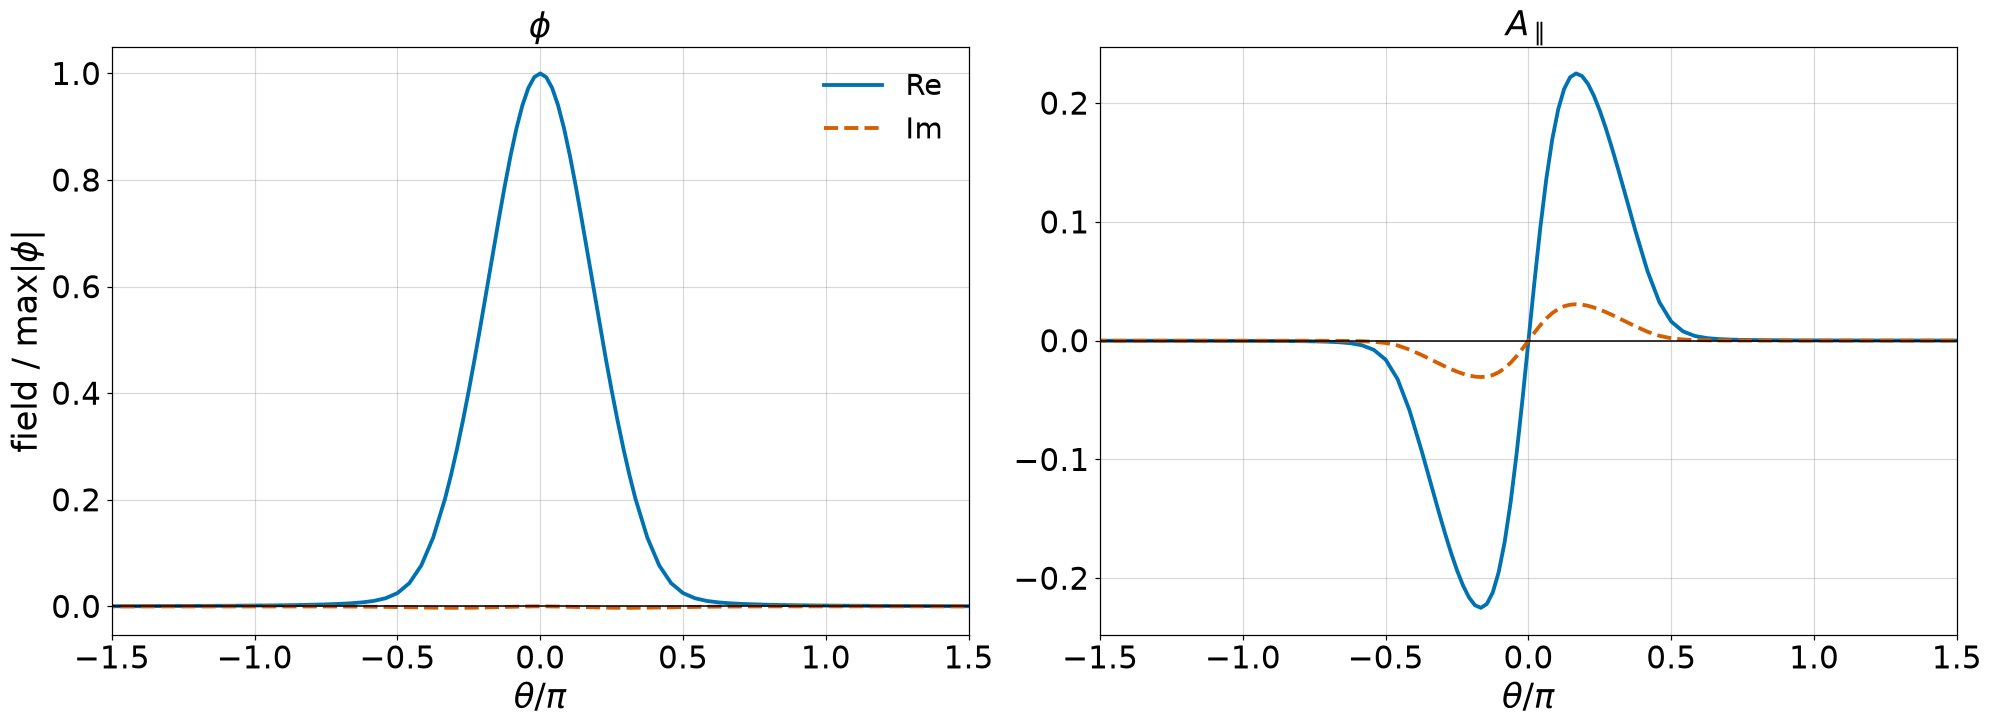

In [2]:
field_labels = {"phi": r"$\phi$", "apar": r"$A_\parallel$"}
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5), sharex=True)
for ax, field in zip(axes, field_labels):
    mode = eigenfunctions.sel(field=field)
    ax.plot(mode.theta / np.pi, mode.real, color="#0072B2", label="Re")
    ax.plot(mode.theta / np.pi, mode.imag, color="#D55E00", ls="--", label="Im")
    ax.axhline(0, color="k", lw=1)
    ax.set(xlabel=r"$\theta/\pi$", title=field_labels[field], xlim=(-1.5, 1.5))
axes[0].set_ylabel(r"field / max$|\phi|$")
axes[0].legend()
fig.savefig(plots_dir / "fig_slide17_kbm_eigenfunction.png", bbox_inches="tight")
plt.show()